### **Cosmetic** **Data Aquisition Project**

Dataset Description

This dataset contains 1,472 cosmetic and skincare products collected from Kaggle. The dataset includes information on product category, brand, product name, price, product rating, ingredients and suitability for different skin types.This dataset will be combined with additional information collected from the Ulta Beauty website.

In [6]:
import pandas as pd
import numpy as np

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt

In [8]:
df = pd.read_csv("cosmetics.csv")

In [9]:
df.head()

,Label,Brand,Name,Price,Rank,Ingredients,Combination,Dry,Normal,Oily,Sensitive
0,Moisturizer,LA MER,Crème de la Mer,175,4.1,"Algae (Seaweed) Extract, Mineral Oil, Petrolat...",1,1,1,1,1
1,Moisturizer,SK-II,Facial Treatment Essence,179,4.1,"Galactomyces Ferment Filtrate (Pitera), Butyle...",1,1,1,1,1
2,Moisturizer,DRUNK ELEPHANT,Protini™ Polypeptide Cream,68,4.4,"Water, Dicaprylyl Carbonate, Glycerin, Ceteary...",1,1,1,1,0
3,Moisturizer,LA MER,The Moisturizing Soft Cream,175,3.8,"Algae (Seaweed) Extract, Cyclopentasiloxane, P...",1,1,1,1,1
4,Moisturizer,IT COSMETICS,Your Skin But Better™ CC+™ Cream with SPF 50+,38,4.1,"Water, Snail Secretion Filtrate, Phenyl Trimet...",1,1,1,1,1


In [10]:
df["Label"].value_counts()

,count
Label,
Moisturizer,298
Cleanser,281
Face Mask,266
Treatment,248
Eye cream,209
Sun protect,170


The Largest Category in the Kaggle Dataset was Moisturizer and the smallest category is Sun Protect

In [11]:
df["Brand"].value_counts().head(10)

,count
Brand,
CLINIQUE,79
SEPHORA COLLECTION,66
SHISEIDO,63
ORIGINS,54
MURAD,47
PETER THOMAS ROTH,46
KIEHL'S SINCE 1851,46
FRESH,44
DR. JART+,41


The dataset contains a large number of skincare brands. Some brands appear much more frequently than others, suggesting a heavier representation of certain manufacturers.

In [12]:
df.shape

(1472, 11)

In [13]:
df.columns

Index(['Label', 'Brand', 'Name', 'Price', 'Rank', 'Ingredients', 'Combination',
       'Dry', 'Normal', 'Oily', 'Sensitive'],
      dtype='object')

The Kaggle dataset contained multiple skincare categories including moisturizers, cleansers, treatments, face masks and eye creams. Equivalent product categories were identified on the Ulta Beauty website and scraped separately to improve compatibility between datasets and increase the likelihood of successful matching.

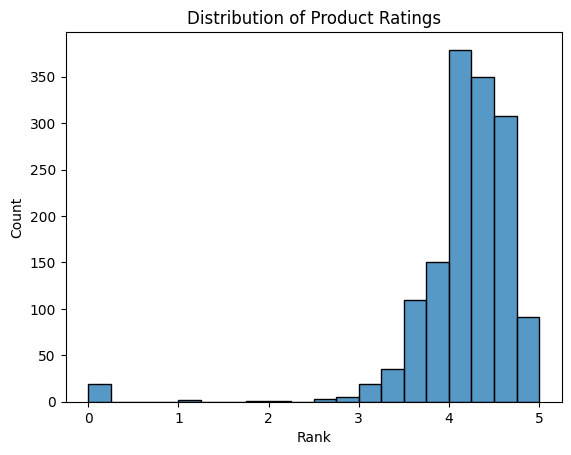

In [14]:
sns.histplot(df["Rank"], bins=20)

plt.title("Distribution of Product Ratings")
plt.show()

Most products achieved ratings above 4.0, indicating generally positive customer evaluations.

## **Scraping Moisturizers**


In [15]:
import requests
from bs4 import BeautifulSoup
import re
import pandas as pd

In [16]:
url = "https://www.ulta.com/shop/skin-care/moisturizers"

headers = {
    "User-Agent": "Mozilla/5.0"
}

response = requests.get(url, headers=headers)

print(response.status_code)

200


In [17]:
ratings = re.findall(
    r'"rating":(.*?),',
    response.text
)

print(ratings[:10])
print(len(ratings))

reviews = re.findall(
    r'"reviewCount":(.*?),',
    response.text
)

print(reviews[:10])
print(len(reviews))

names = re.findall(
    r'"productName":"(.*?)"',
    response.text
)

print(names[:20])
print(len(names))

brands = re.findall(
    r'"brandName":"(.*?)"',
    response.text
)

print(brands[:20])
print(len(brands))

['3.9', '4.6', '4', '4.5', '4.4', '4.6', '4.5', '4.7', '4.7', '4.4']
64
['99', '44668', '2024', '3833', '8600', '1250', '930', '4956', '3117', '4812']
64
['345 Relief Cream', 'Moisture Surge 100H Auto-Replenishing Hydrator Gel Moisturizer with Hyaluronic Acid', 'Toleriane Double Repair Face Moisturizer with Niacinamide', 'Do It All Hydrating Sheer Tinted Moisturizer Balm', 'COMPLEXION RESCUE Tinted Moisturizer with Hyaluronic Acid and Mineral SPF 30', 'The Dewy Skin Cream Line-Plumping Moisturizer', 'Pout Preserve Hydrating Peptide Lip Treatment', 'Vitamin Enriched Face Base+ Moisturizer & Primer with Vitamin C + Hyaluronic Acid', 'Cicaplast Balm B5 Soothing Therapeutic Multi Purpose Cream', 'CC+ Nude Glow Lightweight Foundation + Glow Serum with SPF 40', 'PDRN Hyaluronic Acid 100 Moisturizing Cream', 'Dramatically Different Moisturizing Lotion+Â\xa0For Face', 'Toleriane Double Repair Face Moisturizer UV SPF 30', 'Glow Reviver Melting Lip Balm', 'Halo Glow Liquid Filter', 'Hueguard Ski

In [18]:
soup = BeautifulSoup(response.text, "html.parser")

print(soup.title)

<title data-rh="true">Moisturizers - Skin Care - 2205 Products | Ulta Beauty</title>


In [19]:
moisturizer_df = pd.DataFrame({
    "Brand": brands,
    "Name": names,
    "Ulta_Rating": ratings,
    "Ulta_Review_Count": reviews
})

In [20]:
moisturizer_df["Label"] = "Moisturiser"

In [21]:
moisturizer_df.head()

,Brand,Name,Ulta_Rating,Ulta_Review_Count,Label
0,Dr. Althea,345 Relief Cream,3.9,99,Moisturiser
1,Clinique,Moisture Surge 100H Auto-Replenishing Hydrator...,4.6,44668,Moisturiser
2,La Roche-Posay,Toleriane Double Repair Face Moisturizer with ...,4,2024,Moisturiser
3,IT Cosmetics,Do It All Hydrating Sheer Tinted Moisturizer Balm,4.5,3833,Moisturiser
4,bareMinerals,COMPLEXION RESCUE Tinted Moisturizer with Hyal...,4.4,8600,Moisturiser


In [22]:
moisturizer_df.to_csv(
    "ulta_moisturizer.csv",
    index=False
)

### **Scraping** **Cleansers**

In [23]:
url = "https://www.ulta.com/shop/skin-care/cleansers"

headers = {
    "User-Agent": "Mozilla/5.0"
}

response = requests.get(url, headers=headers)

print(response.status_code)

200


In [24]:
ratings = re.findall(
    r'"rating":(.*?),',
    response.text
)

print(ratings[:10])
print(len(ratings))

reviews = re.findall(
    r'"reviewCount":(.*?),',
    response.text
)

print(reviews[:10])
print(len(reviews))

names = re.findall(
    r'"productName":"(.*?)"',
    response.text
)

print(names[:20])
print(len(names))

brands = re.findall(
    r'"brandName":"(.*?)"',
    response.text
)

print(brands[:20])
print(len(brands))

['4.2', '3.9', '4.6', '4.4', '4.6', '4.6', '4.6', '4.2', '4.4', '4.4']
64
['2170', '209', '3339', '2698', '44668', '151', '44668', '456', '739', '1019']
64
['Glycolic Acid 7% Exfoliating and Brightening Daily Toner', 'Zero Pore Pad', 'Toleriane Purifying Foaming Face Wash for Oily Skin', 'Toleriane Hydrating Gentle Face Cleanser for Dry Skin', 'Take The Day Off Cleansing Balm Makeup Remover', 'PDRN Hyaluronic Acid Hydrating Capsule Mist', 'Take The Day Off Makeup Remover For Lids, Lashes & Lips', 'Hydrating Milky Toner', 'Heartleaf Quercetinol Pore Deep Cleansing Foam', 'Heartleaf Pore Control Cleansing Oil', 'Special Cleansing Gel', 'Clarifying Face Lotion Toner 2 - Dry Combination', 'Clean Towels Original Disposable Face Towels', 'Kojic Acid Turmeric Pad', 'The Rice Wash Skin-Softening Cleanser', 'Foaming Facial Cleanser', 'Rice 70 Glow Milky Toner', 'SkinActive Micellar Cleansing Water All-in-1 Cleanser & Makeup Remover', 'Purity Made Simple One-Step Facial Cleanser', 'Precleanse Cl

In [25]:
cleanser_df = pd.DataFrame({
    "Brand": brands,
    "Name": names,
    "Ulta_Rating": ratings,
    "Ulta_Review_Count": reviews
})

In [26]:
cleanser_df["Label"] = "Cleanser"

In [27]:
cleanser_df.head()

,Brand,Name,Ulta_Rating,Ulta_Review_Count,Label
0,The Ordinary,Glycolic Acid 7% Exfoliating and Brightening D...,4.2,2170,Cleanser
1,medicube,Zero Pore Pad,3.9,209,Cleanser
2,La Roche-Posay,Toleriane Purifying Foaming Face Wash for Oily...,4.6,3339,Cleanser
3,La Roche-Posay,Toleriane Hydrating Gentle Face Cleanser for D...,4.4,2698,Cleanser
4,Clinique,Take The Day Off Cleansing Balm Makeup Remover,4.6,44668,Cleanser


In [28]:
cleanser_df.to_csv(
    "ulta_Cleanser.csv",
    index=False
)

### **Scraping Eye Creams**


In [29]:
url = "https://www.ulta.com/shop/skin-care/eye-treatments/eye-cream"

headers = {
    "User-Agent": "Mozilla/5.0"
}

response = requests.get(url, headers=headers)

print(response.status_code)

200


In [30]:
ratings = re.findall(
    r'"rating":(.*?),',
    response.text
)

print(ratings[:10])
print(len(ratings))

reviews = re.findall(
    r'"reviewCount":(.*?),',
    response.text
)

print(reviews[:10])
print(len(reviews))

names = re.findall(
    r'"productName":"(.*?)"',
    response.text
)

print(names[:20])
print(len(names))

brands = re.findall(
    r'"brandName":"(.*?)"',
    response.text
)

print(brands[:20])
print(len(brands))

['4.6', '4.6', '4.6', '4.6', '3.4', '4.5', '4.5', '4.4', '4.3', '4.5']
64
['44668', '117', '5685', '44668', '49', '1296', '109', '5613', '886', '5774']
64
['All About Eyes Eye Cream with Vitamin C', 'Lacto-PDRN 4% + B9 Eye Cream', 'Luminous Eye Corrector SPF 41', 'Clinique Smart Clinical Repair Wrinkle Correcting Eye Cream', 'Calcium Volume Multi Balm', 'All About Eyes Rich Eye Cream with Hyaluronic Acid', 'PDRN Caffeine Rejuvenating Eye Cream', 'Total Eye Lift Refillable Eye Cream', 'Creamy Eye Treatment with Avocado', 'â\x80\x98Spresso Energizing Eye Balm', 'Yerba Mate Wake Up Eye Gel', 'Advanced Night Repair Eye Lift + Sculpt Eye Cream', 'Derm Correxion Eye Repair Dark Circle Eye Cream', 'Benefiance Wrinkle Smoothing Eye Cream', 'Confidence in an Eye Cream Anti-Aging Peptide Eye Cream', 'Firming Peptide Eye Cream', 'Banana Bright+ Vitamin C Eye CrÃ¨me for Dark Circles', 'Pure Radiance Brightening Eye Cream', 'Advanced Night Repair Eye Gel-Cream for Dark Circles', 'Phyto Nature Lifti

In [31]:
EyeCream_df = pd.DataFrame({
    "Brand": brands,
    "Name": names,
    "Ulta_Rating": ratings,
    "Ulta_Review_Count": reviews
})

In [32]:
EyeCream_df["Label"] = "EyeCream"

In [33]:
EyeCream_df.head()

,Brand,Name,Ulta_Rating,Ulta_Review_Count,Label
0,Clinique,All About Eyes Eye Cream with Vitamin C,4.6,44668,EyeCream
1,The Ordinary,Lacto-PDRN 4% + B9 Eye Cream,4.6,117,EyeCream
2,DRMTLGY,Luminous Eye Corrector SPF 41,4.6,5685,EyeCream
3,Clinique,Clinique Smart Clinical Repair Wrinkle Correct...,4.6,44668,EyeCream
4,Dr. Melaxin,Calcium Volume Multi Balm,3.4,49,EyeCream


In [34]:
EyeCream_df.to_csv(
    "ulta_EyeCream.csv",
    index=False
)

# **Scraping Face Masks**

In [35]:
url = "https://www.ulta.com/shop/skin-care/treatment-serums/face-masks"

headers = {
    "User-Agent": "Mozilla/5.0"
}

response = requests.get(url, headers=headers)

print(response.status_code)

200


In [36]:
ratings = re.findall(
    r'"rating":(.*?),',
    response.text
)

print(ratings[:10])
print(len(ratings))

reviews = re.findall(
    r'"reviewCount":(.*?),',
    response.text
)

print(reviews[:10])
print(len(reviews))

names = re.findall(
    r'"productName":"(.*?)"',
    response.text
)

print(names[:20])
print(len(names))

brands = re.findall(
    r'"brandName":"(.*?)"',
    response.text
)

print(brands[:20])
print(len(brands))

['3.7', '3.8', '3.6', '3.8', '4.6', '4.7', '4.4', '4.7', '4.6', '4.3']
64
['100', '127', '57', '13', '448', '959', '241', '86', '1051', '570']
64
['PDRN Pink Collagen Gel Mask', 'Collagen Night Wrapping Mask', 'Kojic Acid Turmeric Night Wrapping Mask', 'Kojic Acid Turmeric Gel Mask', 'Smart Clinical Repair Overnight Recovery Face Cream + Mask', 'Moisture Surge Overnight Face Mask', 'Bio-Collagen Radiance Facial Mask', 'Deep Collagen Power Boosting Overnight Sheet Mask', 'The POREfessional Deep Retreat Pore-Clearing Clay Mask', 'Salicylic Acid 2% Masque Clarifying Charcoal & Clay Mask for Blemish Prone Skin', 'Peanuts x UBC Face Mask Set', 'Madagascar Centella Poremizing Quick Clay Stick Mask', 'Pumpkin Enzyme Clarifying Mask', 'Advanced Snail Mucin Glass Glow Hydrogel Mask', 'Mask Melt PDRN + Hyaluronic Acid Overnight Hydrogel Mask', 'PDRN Exosome Skinplaning Glaze Mask with Collagen & Peptide', 'Mask Melt Collagen + Peptide Overnight Hydrogel Mask', 'Clear Improvement Active Charcoal 

In [37]:
FaceMask_df = pd.DataFrame({
    "Brand": brands,
    "Name": names,
    "Ulta_Rating": ratings,
    "Ulta_Review_Count": reviews
})

In [38]:
FaceMask_df["Label"] = "FaceMask"

In [39]:
FaceMask_df.head()

,Brand,Name,Ulta_Rating,Ulta_Review_Count,Label
0,medicube,PDRN Pink Collagen Gel Mask,3.7,100,FaceMask
1,medicube,Collagen Night Wrapping Mask,3.8,127,FaceMask
2,medicube,Kojic Acid Turmeric Night Wrapping Mask,3.6,57,FaceMask
3,medicube,Kojic Acid Turmeric Gel Mask,3.8,13,FaceMask
4,Clinique,Smart Clinical Repair Overnight Recovery Face ...,4.6,448,FaceMask


In [40]:
FaceMask_df.to_csv(
    "ulta_FaceMask.csv",
    index=False
)

### **Scraping Sun protect**

In [41]:
url = "https://www.ulta.com/shop/body-care/suncare/sunscreen"

headers = {
    "User-Agent": "Mozilla/5.0"
}

response = requests.get(url, headers=headers)

print(response.status_code)

200


In [42]:
ratings = re.findall(
    r'"rating":(.*?),',
    response.text
)

print(ratings[:10])
print(len(ratings))

reviews = re.findall(
    r'"reviewCount":(.*?),',
    response.text
)

print(reviews[:10])
print(len(reviews))

names = re.findall(
    r'"productName":"(.*?)"',
    response.text
)

print(names[:20])
print(len(names))

brands = re.findall(
    r'"brandName":"(.*?)"',
    response.text
)

print(brands[:20])
print(len(brands))

['4.7', '4.6', '4.3', '4.5', '4.5', '4.5', '4.5', '4.7', '4.9', '4.1']
64
['1109', '5685', '2657', '3792', '259', '1799', '329', '932', '297', '2086']
64
['Unseen Sunscreen SPF 50 Invisible Sun Protection', 'Luminous Eye Corrector SPF 41', 'Anthelios Mineral Tinted Ultra Light Face Sunscreen Fluid SPF 50', 'Glowscreen SPF 40 Sunscreen with Hyaluronic Acid + Niacinamide', 'Zero-Cast Moisturizing Finish Sunscreen', 'Mineral Mattescreen SPF 40', 'Toleriane Double Repair Matte Face Moisturizer with SPF30', 'Madagascar Centella Hyalu-Cica Water-Fit Sun Serum UV SPF50', 'The Milky Sunscreen SPF 50+ PA++++', 'Anthelios Clear Skin Dry Touch Face Sunscreen SPF 60', 'Anthelios Ultra Light Fluid Face Sunscreen SPF 60', 'Moisturizing Sunscreen Lotion SPF 30', 'Anthelios UV Air Daily Supercharged Serum Sunscreen SPF 50', 'Dramatically Different Moisturizing Lotion+ SPF35 for Face', 'UV Filters SPF 45 Serum', 'Anthelios Mineral Ultra-Light Face Sunscreen Fluid SPF 50', 'Anthelios Melt-in Milk Body &

In [43]:
SunProtect_df = pd.DataFrame({
    "Brand": brands,
    "Name": names,
    "Ulta_Rating": ratings,
    "Ulta_Review_Count": reviews
})

In [44]:
SunProtect_df["Label"] = "Sun protect"

In [45]:
SunProtect_df.head()

,Brand,Name,Ulta_Rating,Ulta_Review_Count,Label
0,Supergoop!,Unseen Sunscreen SPF 50 Invisible Sun Protection,4.7,1109,Sun protect
1,DRMTLGY,Luminous Eye Corrector SPF 41,4.6,5685,Sun protect
2,La Roche-Posay,Anthelios Mineral Tinted Ultra Light Face Suns...,4.3,2657,Sun protect
3,Supergoop!,Glowscreen SPF 40 Sunscreen with Hyaluronic Ac...,4.5,3792,Sun protect
4,ANUA,Zero-Cast Moisturizing Finish Sunscreen,4.5,259,Sun protect


In [46]:
SunProtect_df.to_csv(
    "ulta_SunProtect.csv",
    index=False
)

### **Scraping Treatment**

In [47]:
url = "https://www.ulta.com/shop/skin-care/treatment-serums"

headers = {
    "User-Agent": "Mozilla/5.0"
}

response = requests.get(url, headers=headers)

print(response.status_code)

200


In [48]:
ratings = re.findall(
    r'"rating":(.*?),',
    response.text
)

print(ratings[:10])
print(len(ratings))

reviews = re.findall(
    r'"reviewCount":(.*?),',
    response.text
)

print(reviews[:10])
print(len(reviews))

names = re.findall(
    r'"productName":"(.*?)"',
    response.text
)

print(names[:20])
print(len(names))

brands = re.findall(
    r'"brandName":"(.*?)"',
    response.text
)

print(brands[:20])
print(len(brands))

['4.3', '4.6', '4.7', '4.7', '4.7', '3', '3.7', '4.2', '4.5', '4.5']
64
['1327', '411', '5625', '3117', '5511', '53', '100', '6002', '22181', '811']
64
['Hyaluronic Acid 2% + B5 Hydrating Serum with Ceramides', 'Azelaic Acid 10 Hyaluron Redness Soothing Serum', 'Mighty Patch Original Acne Pimple Patches', 'Cicaplast Balm B5 Soothing Therapeutic Multi Purpose Cream', 'Daily Microfoliant Exfoliator', 'PDRN Pink Collagen Volume Multi Balm', 'PDRN Pink Collagen Gel Mask', 'Niacinamide 10% + Zinc 1% Serum for Oily Skin', 'Advanced Night Repair Multi-Recovery Complex Serum with Hyaluronic Acid & Peptides', 'Niacinamide 10 TXA 4 Serum for Brightening and Dark Spots', 'Glass Skin Ginseng Collagen Mask', 'Azelaic Acid Suspension 10% Cream for Redness and Blemish-Prone Skin', 'DOUBLE SERUM Age-Defying Concentrate', 'Multi-Peptide + Copper Peptides 1% for Wrinkles and Skin Elasticity', 'Clinique Smart Clinical Repair Wrinkle Correcting Serum', 'Discoloration Correcting Serum', 'Hyalu B5 Pure Hyal

In [49]:
Treatment_df = pd.DataFrame({
    "Brand": brands,
    "Name": names,
    "Ulta_Rating": ratings,
    "Ulta_Review_Count": reviews
})

In [50]:
Treatment_df["Label"] = "Treatment"

In [51]:
Treatment_df.head()

,Brand,Name,Ulta_Rating,Ulta_Review_Count,Label
0,The Ordinary,Hyaluronic Acid 2% + B5 Hydrating Serum with C...,4.3,1327,Treatment
1,ANUA,Azelaic Acid 10 Hyaluron Redness Soothing Serum,4.6,411,Treatment
2,Hero Cosmetics,Mighty Patch Original Acne Pimple Patches,4.7,5625,Treatment
3,La Roche-Posay,Cicaplast Balm B5 Soothing Therapeutic Multi P...,4.7,3117,Treatment
4,Dermalogica,Daily Microfoliant Exfoliator,4.7,5511,Treatment


In [52]:
Treatment_df.to_csv(
    "ulta_treatment.csv",
    index=False
)

Merge All these datatset

In [53]:
ulta_df = pd.concat([
    moisturizer_df,
    cleanser_df,
    EyeCream_df,
    FaceMask_df,
    Treatment_df,
    SunProtect_df
], ignore_index=True)

In [54]:
ulta_df.shape

(384, 5)

In [55]:
ulta_df.head()

,Brand,Name,Ulta_Rating,Ulta_Review_Count,Label
0,Dr. Althea,345 Relief Cream,3.9,99,Moisturiser
1,Clinique,Moisture Surge 100H Auto-Replenishing Hydrator...,4.6,44668,Moisturiser
2,La Roche-Posay,Toleriane Double Repair Face Moisturizer with ...,4,2024,Moisturiser
3,IT Cosmetics,Do It All Hydrating Sheer Tinted Moisturizer Balm,4.5,3833,Moisturiser
4,bareMinerals,COMPLEXION RESCUE Tinted Moisturizer with Hyal...,4.4,8600,Moisturiser


In [56]:
ulta_df.to_csv(
    "Full_Ulta_Datset.csv",
    index=False
)

In [57]:
ulta_df.to_csv("Full_Ulta_Dataset.csv", index=False)

Merge Strategy

The Kaggle dataset and Ulta dataset were compared using Brand and product category information. Initially a merge was attempted using Brand alone; however this produced inaccurate matches because a single brand often sells multiple products within a category.

A second merge approach was used to improve matching accuracy. Although only a small number of exact matches were identified, the exercise demonstrated the challenges associated with integrating datasets from different sources.

In [58]:
df["Label"] = df["Label"].str.strip()
ulta_df["Label"] = ulta_df["Label"].str.strip()

merged_df = pd.merge(
    df,
    ulta_df,
    on=["Brand", "Label"],
    how="left"
)

print(merged_df.shape)
merged_df.head()

(1476, 14)


,Label,Brand,Name_x,Price,Rank,Ingredients,Combination,Dry,Normal,Oily,Sensitive,Name_y,Ulta_Rating,Ulta_Review_Count
0,Moisturizer,LA MER,Crème de la Mer,175,4.1,"Algae (Seaweed) Extract, Mineral Oil, Petrolat...",1,1,1,1,1,NaN,NaN,NaN
1,Moisturizer,SK-II,Facial Treatment Essence,179,4.1,"Galactomyces Ferment Filtrate (Pitera), Butyle...",1,1,1,1,1,NaN,NaN,NaN
2,Moisturizer,DRUNK ELEPHANT,Protini™ Polypeptide Cream,68,4.4,"Water, Dicaprylyl Carbonate, Glycerin, Ceteary...",1,1,1,1,0,NaN,NaN,NaN
3,Moisturizer,LA MER,The Moisturizing Soft Cream,175,3.8,"Algae (Seaweed) Extract, Cyclopentasiloxane, P...",1,1,1,1,1,NaN,NaN,NaN
4,Moisturizer,IT COSMETICS,Your Skin But Better™ CC+™ Cream with SPF 50+,38,4.1,"Water, Snail Secretion Filtrate, Phenyl Trimet...",1,1,1,1,1,NaN,NaN,NaN


In [59]:
matched_df = merged_df[
    merged_df["Ulta_Rating"].notnull()
]

matched_df.shape

(14, 14)

In [60]:
matched_df.head()

,Label,Brand,Name_x,Price,Rank,Ingredients,Combination,Dry,Normal,Oily,Sensitive,Name_y,Ulta_Rating,Ulta_Review_Count
301,Cleanser,FARMACY,Green Clean Makeup Meltaway Cleansing Balm wit...,34,4.6,"Cetyl Ethylhexanoate, Caprylic/Capric Triglyce...",1,1,1,1,1,Green Clean Cleansing Balm,4.9,2668
305,Cleanser,TATCHA,The Rice Polish Foaming Enzyme Powder,65,4.4,"Microcrystalline Cellulose, Oryza Sativa (Rice...",1,1,1,1,1,The Rice Wash Skin-Softening Cleanser,4.4,79
306,Cleanser,TATCHA,The Rice Polish Foaming Enzyme Powder,65,4.4,"Microcrystalline Cellulose, Oryza Sativa (Rice...",1,1,1,1,1,The Matcha Foam Pore-Refining & Oil-Balancing ...,4.9,463
311,Cleanser,TATCHA,The Deep Cleanse,38,4.4,* Hadasei-3,1,0,1,1,1,The Rice Wash Skin-Softening Cleanser,4.4,79
312,Cleanser,TATCHA,The Deep Cleanse,38,4.4,* Hadasei-3,1,0,1,1,1,The Matcha Foam Pore-Refining & Oil-Balancing ...,4.9,463


In [61]:
merged_df["Ulta_Review_Count"].notnull().sum()

np.int64(14)

In [62]:
merged_df.to_csv(
    "merged_data.csv",
    index=False
)

Limitations of the Merge

The Kaggle and Ulta datasets contained different product catalogues. Although common fields such as Brand and Label were available, many products did not have exact matches between datasets. As a result, only a small subset of products could be successfully linked.

This highlights a common challenge in real-world data integration, where datasets from different sources often use different product ranges, naming conventions and levels of detail.

In [63]:
matched_df

,Label,Brand,Name_x,Price,Rank,Ingredients,Combination,Dry,Normal,Oily,Sensitive,Name_y,Ulta_Rating,Ulta_Review_Count
301,Cleanser,FARMACY,Green Clean Makeup Meltaway Cleansing Balm wit...,34,4.6,"Cetyl Ethylhexanoate, Caprylic/Capric Triglyce...",1,1,1,1,1,Green Clean Cleansing Balm,4.9,2668
305,Cleanser,TATCHA,The Rice Polish Foaming Enzyme Powder,65,4.4,"Microcrystalline Cellulose, Oryza Sativa (Rice...",1,1,1,1,1,The Rice Wash Skin-Softening Cleanser,4.4,79
306,Cleanser,TATCHA,The Rice Polish Foaming Enzyme Powder,65,4.4,"Microcrystalline Cellulose, Oryza Sativa (Rice...",1,1,1,1,1,The Matcha Foam Pore-Refining & Oil-Balancing ...,4.9,463
311,Cleanser,TATCHA,The Deep Cleanse,38,4.4,* Hadasei-3,1,0,1,1,1,The Rice Wash Skin-Softening Cleanser,4.4,79
312,Cleanser,TATCHA,The Deep Cleanse,38,4.4,* Hadasei-3,1,0,1,1,1,The Matcha Foam Pore-Refining & Oil-Balancing ...,4.9,463
364,Cleanser,FARMACY,Clean Bee Ultra Gentle Facial Cleanser,28,4.3,"Water, Sodium Lauroyl Methyl Isethionate, Coca...",1,1,1,1,1,Green Clean Cleansing Balm,4.9,2668
449,Cleanser,TATCHA,Aburatorigami Japanese Blotting Papers,12,4.7,"Abaca Leaf, Gold Flakes.",1,1,1,1,1,The Rice Wash Skin-Softening Cleanser,4.4,79
450,Cleanser,TATCHA,Aburatorigami Japanese Blotting Papers,12,4.7,"Abaca Leaf, Gold Flakes.",1,1,1,1,1,The Matcha Foam Pore-Refining & Oil-Balancing ...,4.9,463
477,Cleanser,FARMACY,New Day Gentle Exfoliating Grains,30,4.5,"Sodium Cocoyl Isethionate, Zea Mays (Corn) Sta...",1,1,1,1,1,Green Clean Cleansing Balm,4.9,2668
583,Treatment,SUNDAY RILEY,Good Genes All-In-One Lactic Acid Treatment,158,4.3,"Opuntia Tuna Fruit (Prickly Pear) Extract, Aga...",1,1,1,1,0,Good Genes All-In-One Lactic Acid Treatment,4.6,2853


## Data Quality Issues

There were some challenges during data integration



1.   Product names were often between datasets
2.   Some brands available in the Kaggle Dataset were not available in the scraped Ulta Categories

1.   Product Descriptions and naming conventions varied across sources
2.   The Merge therefore resulted in relatively few successful matches





Dataset Integration

The Kaggle cosmetics dataset and the Ulta Beauty dataset were merged using the variables Brand and Label.
Prior to merging, category labels were standardized to ensure consistency between datasets.
Some brands appeared in both datasets, allowing successful matches to be created.

Challenges Encountered

A relatively small number of exact matches were found.
Many products available on Ulta were not present in the Kaggle dataset and vice versa.
Differences in brand naming conventions, product ranges, and category labels reduced the number of successful matches.

Data Quality

Missing values were present after the merge because not every Kaggle product had a corresponding Ulta product.
These unmatched records were retained using a left join to preserve the integrity of the original dataset.

Implications

The limited number of matches suggests that the two datasets represent different product selections.
Results based on matched products should therefore be interpreted cautiously.
Despite the low match rate, the merged dataset still provides useful insights into how customer ratings and review activity compare across sources.

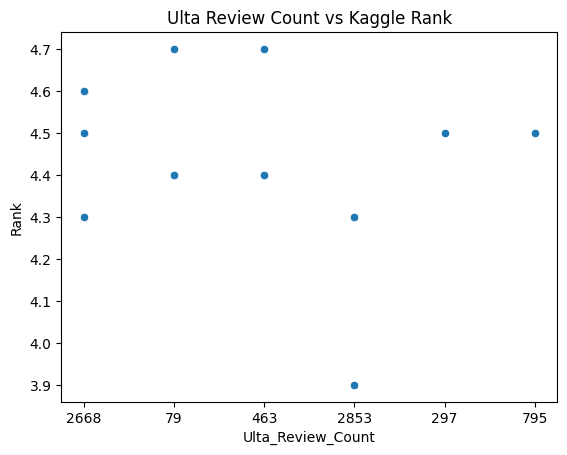

In [64]:
sns.scatterplot(
    data=matched_df,
    x="Ulta_Review_Count",
    y="Rank"
)

plt.title("Ulta Review Count vs Kaggle Rank")
plt.show()

Visualisation 1: Ulta Review Count vs Kaggle Rank

A scatter plot was used to investigate the relationship between customer review counts from the Ulta dataset and product rankings from the Kaggle dataset. Most matched products had ratings between 4.3 and 4.7 regardless of the number of reviews received. Due to the relatively small number of successfully matched products, no strong relationship was observed between review count and ranking

In [65]:
matched_df.columns

Index(['Label', 'Brand', 'Name_x', 'Price', 'Rank', 'Ingredients',
       'Combination', 'Dry', 'Normal', 'Oily', 'Sensitive', 'Name_y',
       'Ulta_Rating', 'Ulta_Review_Count'],
      dtype='object')

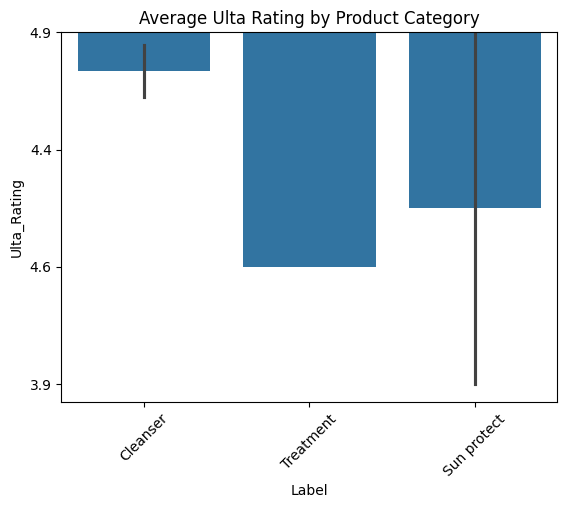

In [66]:
sns.barplot(
    data=matched_df,
    x="Label",
    y="Ulta_Rating"
)

plt.xticks(rotation=45)
plt.title("Average Ulta Rating by Product Category")
plt.show()

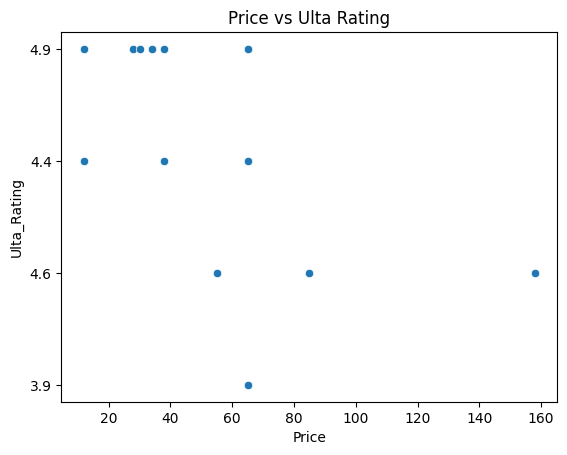

In [67]:
sns.scatterplot(
    data=matched_df,
    x="Price",
    y="Ulta_Rating"
)

plt.title("Price vs Ulta Rating")
plt.show()

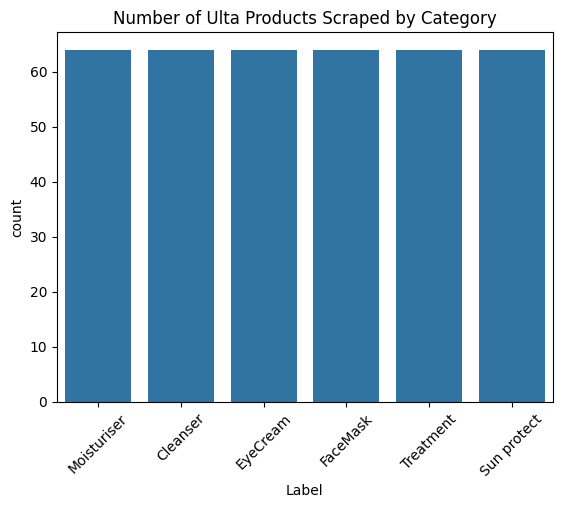

In [68]:
sns.countplot(
    data=ulta_df,
    x="Label"
)

plt.xticks(rotation=45)
plt.title("Number of Ulta Products Scraped by Category")
plt.show()

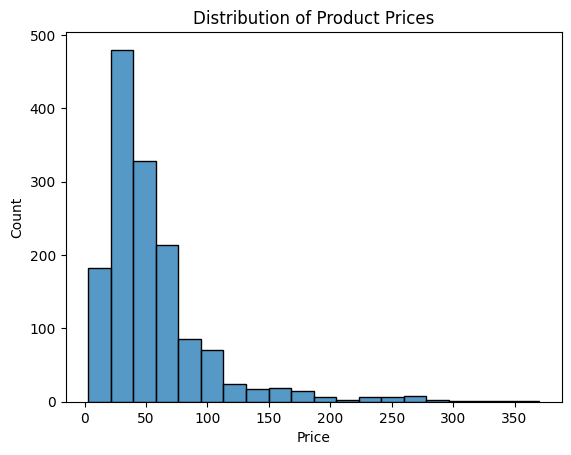

In [69]:
sns.histplot(df["Price"], bins=20)

plt.title("Distribution of Product Prices")
plt.show()

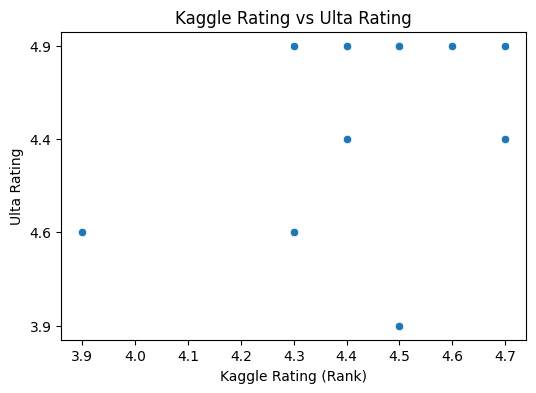

In [70]:
plt.figure(figsize=(6,4))

sns.scatterplot(
    data=matched_df,
    x="Rank",
    y="Ulta_Rating"
)

plt.title("Kaggle Rating vs Ulta Rating")
plt.xlabel("Kaggle Rating (Rank)")
plt.ylabel("Ulta Rating")
plt.show()

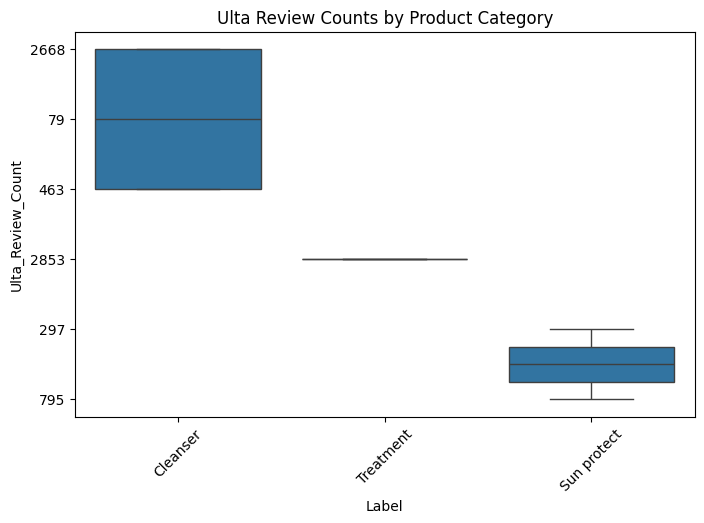

In [71]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=matched_df,
    x="Label",
    y="Ulta_Review_Count"
)

plt.title("Ulta Review Counts by Product Category")
plt.xticks(rotation=45)
plt.show()

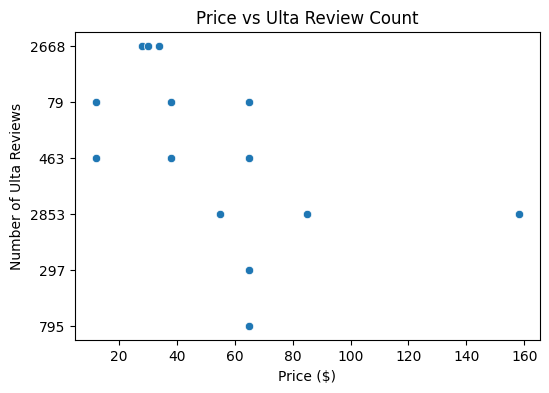

In [72]:
plt.figure(figsize=(6,4))

sns.scatterplot(
    data=matched_df,
    x="Price",
    y="Ulta_Review_Count"
)

plt.title("Price vs Ulta Review Count")
plt.xlabel("Price ($)")
plt.ylabel("Number of Ulta Reviews")
plt.show()

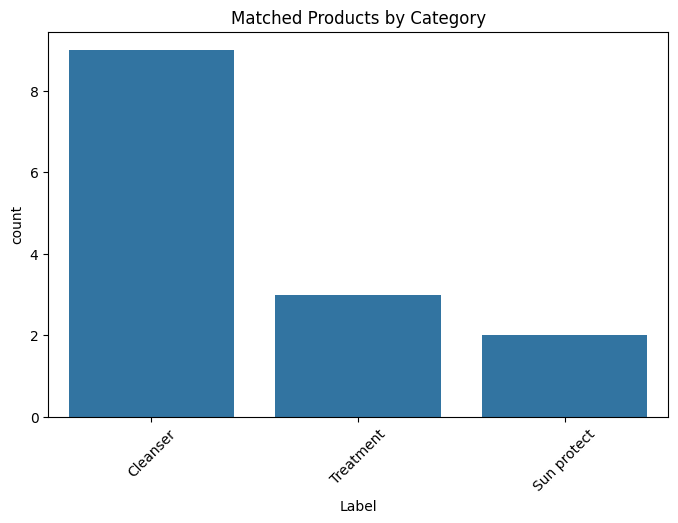

In [73]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=matched_df,
    x="Label"
)

plt.title("Matched Products by Category")
plt.xticks(rotation=45)
plt.show()